In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Styling config for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
print("Data Science Setup Ready!")

Data Science Setup Ready!


In [3]:
df = pd.read_csv('delhivery_data.csv')

# If delay_minutes is not directly present, calculate it
if 'delay_minutes' not in df.columns:
    df['delay_minutes'] = df['actual_time'] - df['osrm_time']

# Fill or drop missing values in key columns
df.dropna(subset=['delay_minutes', 'source_name', 'destination_name'], inplace=True)

# Basic shape and data check
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (144316, 25)


,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor,delay_minutes
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,10.435660,14.0,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727,3.0
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,18.936842,24.0,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111,4.0
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,27.637279,40.0,28.0,32.5395,1.428571,16.0,7.0,10.8152,2.285714,12.0
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,36.118028,62.0,40.0,45.5620,1.550000,21.0,12.0,13.0224,1.750000,22.0
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,39.386040,68.0,44.0,54.2181,1.545455,6.0,5.0,3.9153,1.200000,24.0


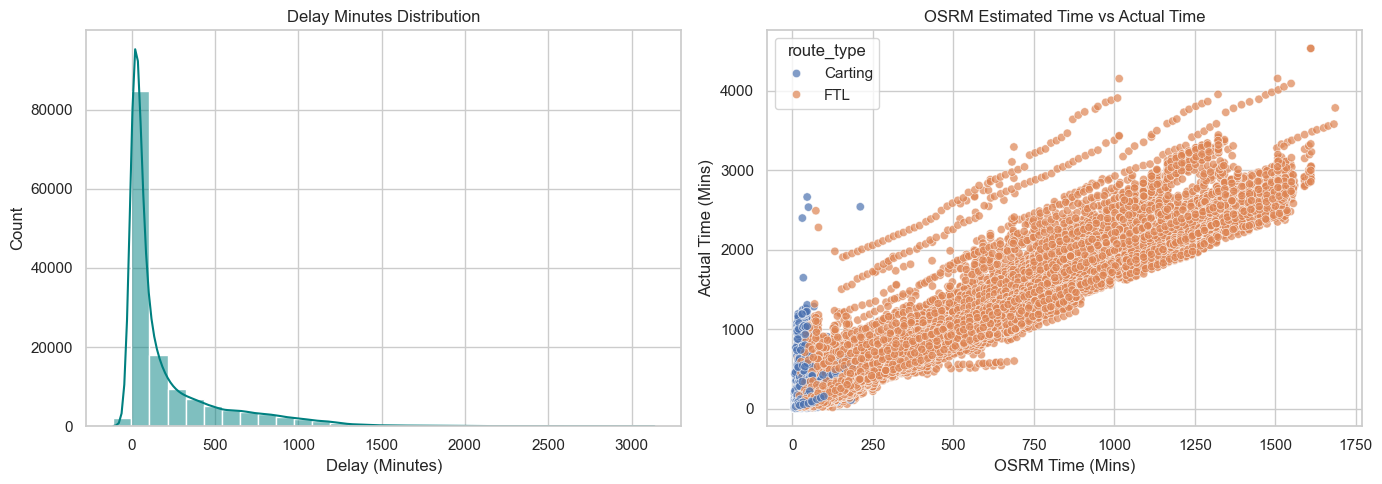

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Delay Distribution Plot
sns.histplot(df['delay_minutes'], kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title('Delay Minutes Distribution')
axes[0].set_xlabel('Delay (Minutes)')

# 2. Actual Time vs OSRM Estimated Time Scatter Plot
sns.scatterplot(x='osrm_time', y='actual_time', hue='route_type', data=df, ax=axes[1], alpha=0.7)
axes[1].set_title('OSRM Estimated Time vs Actual Time')
axes[1].set_xlabel('OSRM Time (Mins)')
axes[1].set_ylabel('Actual Time (Mins)')

plt.tight_layout()
plt.show()

In [7]:
# If avg_speed is missing, compute it on the fly
if 'avg_speed' not in df.columns:
    # Adding a small epsilon to actual_time to avoid division by zero
    df['avg_speed'] = df['actual_distance_to_destination'] / ((df['actual_time'] + 0.001) / 60.0)

categorical_features = ['route_type']
numeric_features = ['actual_distance_to_destination', 'osrm_time', 'osrm_distance', 'avg_speed']

X = df[categorical_features + numeric_features]
y = df['delay_minutes']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training Samples: {len(X_train)} | Testing Samples: {len(X_test)}")

Training Samples: 115452 | Testing Samples: 28864


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Pipeline binding Preprocessor with RandomForestRegressor
ml_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Train Model
print("Training RandomForest Regression Model...")
ml_pipeline.fit(X_train, y_train)
print("Model Training Complete!")

Training RandomForest Regression Model...
Model Training Complete!


In [9]:
y_pred = ml_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("="*40)
print("MODEL PERFORMANCE EVALUATION METRICS")
print("="*40)
print(f"Mean Absolute Error (MAE) : {mae:.2f} mins")
print(f"Root Mean Squared Error (RMSE) : {rmse:.2f} mins")
print(f"R2 Score : {r2:.4f}")

# Financial Impact Estimation (₹150/hr penalty conversion)
total_predicted_loss_inr = (np.sum(np.maximum(y_pred, 0)) / 60.0) * 150
print(f"Predicted Test Set Financial Loss: ₹{total_predicted_loss_inr:,.2f}")

MODEL PERFORMANCE EVALUATION METRICS
Mean Absolute Error (MAE) : 3.08 mins
Root Mean Squared Error (RMSE) : 12.36 mins
R2 Score : 0.9984
Predicted Test Set Financial Loss: ₹14,711,283.57
